# ENG 2440 Assignment 2 — Whole-Tumor Segmentation in Multimodal MRI

**Author:** <Yintong Wang> (<25011183>)  
**Repository:** <GitHub link>

Run cells top to bottom. Change **only** the `DATA_ROOT` cell below.
Note: Interpretation serves as a preliminary draft for report. Detailed response recorded in report.

## 0. Configuration

### ⚠️ DATA_ROOT — the only line you should need to change

In [1]:
from pathlib import Path

DATA_ROOT = Path("Task01_BrainTumour") 
SPLIT_FILE = Path("assignment2_split.csv")
CACHE_DIR = Path("cache")
OUT_DIR = Path("outputs")
SEED = 0  # Call seed_everything(SEED) before building each model

In [2]:
import random
import time
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import nibabel as nib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy import ndimage
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm



if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
OUT_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)

print(f"torch {torch.__version__} | nibabel {nib.__version__} | device: {DEVICE} | seed: {SEED}")

torch 2.14.1 | nibabel 5.4.2 | device: mps | seed: 0


### Setup check (from the assignment brief)

In [3]:
import pandas as pd

split_df = pd.read_csv(SPLIT_FILE)

assert len(split_df) == 484
assert set(split_df["split"]) == {"train", "validation", "test"}
for row in split_df.itertuples():
    assert (DATA_ROOT / row.image_relpath).exists()
    assert (DATA_ROOT / row.label_relpath).exists()
print(split_df["split"].value_counts())

split
train         338
test           73
validation     73
Name: count, dtype: int64


## A. Task definition and volume inspection (10)

### A1. Input, output, unit of analysis, intended use; voxel / slice / volume / case [2]

In [4]:


row = split_df.iloc[0]
img = nib.load(DATA_ROOT / row.image_relpath)
lab = nib.load(DATA_ROOT / row.label_relpath)


vx, vy, vz = img.header.get_zooms()[:3] # voxel sizes (mm)
voxel_ml = vx * vy * vz / 1000 # voxel volume (mL)

print(f"Example case {row.case_id}: image shape {img.shape}, voxel size {vx} x {vy} x {vz} mm, voxel volume {voxel_ml} mL")



Example case BRATS_001: image shape (240, 240, 155, 4), voxel size 1.0 x 1.0 x 1.0 mm, voxel volume 0.0010000000474974513 mL


_Interpretation:_

Input: a 4-channel 3d MRI volume per patient

Output: a binary whole-tumor mask of the same grid

Unit: each patient case

Intended use: research

Voxel: a 3d element of a pixel.
Slice: a 2d plane
Volume: 3d array
Case: all data for one patient


### A2. ≥3 cases: shape, channel order, affine, orientation codes, spacing, label values [3]

In [5]:
channel_order = ["FLAIR", "T1w", "t1gd", "T2w"]
print("Channel order:", channel_order)

for r in split_df.head(3).itertuples():
    img = nib.load(DATA_ROOT / r.image_relpath)
    lab = nib.load(DATA_ROOT / r.label_relpath)
    print(f"Case {r.case_id}: image shape {img.shape}, label shape {lab.shape}")
    print(f"affine:\n{img.affine}\n{lab.affine}")
    print(f"Orientation: {''.join(nib.aff2axcodes(img.affine))} | {''.join(nib.aff2axcodes(lab.affine))}")

    print(f"Spacing: {img.header.get_zooms()[:3]} | {lab.header.get_zooms()[:3]}")
    print(f"labels: {np.unique(lab.get_fdata())}")





Channel order: ['FLAIR', 'T1w', 't1gd', 'T2w']
Case BRATS_001: image shape (240, 240, 155, 4), label shape (240, 240, 155)
affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Orientation: RAS | RAS
Spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0)) | (np.float32(1.0), np.float32(1.0), np.float32(1.0))
labels: [0. 1. 2. 3.]
Case BRATS_002: image shape (240, 240, 155, 4), label shape (240, 240, 155)
affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Orientation: RAS | RAS
Spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0)) | (np.float32(1.0), np.float32(1.0), np.float32(1.0))
labels: [0. 1. 2. 3.]
Case BRATS_003: image shape (240, 240, 155, 4), label shape (240, 240, 155)
affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Orientation: RA

_Interpretation:_ 

From the three cases checked, all are identical interms of shape. Images are stored as 4d arrays with shape (240, 240, 155, 4), where 4 suggests 4 channels, and labels as (240, 240, 155, 4).

Channel order from `dataset.json` is ['FLAIR', 'T1w', 't1gd', 'T2w'].

Orientation codes are RAS (image and label), spacing 1* 1* 1 mm, so 1 voxel = 0.001 mL.

### A3. FLAIR, T1, T1ce, T2 + mask at the same physical location [2]

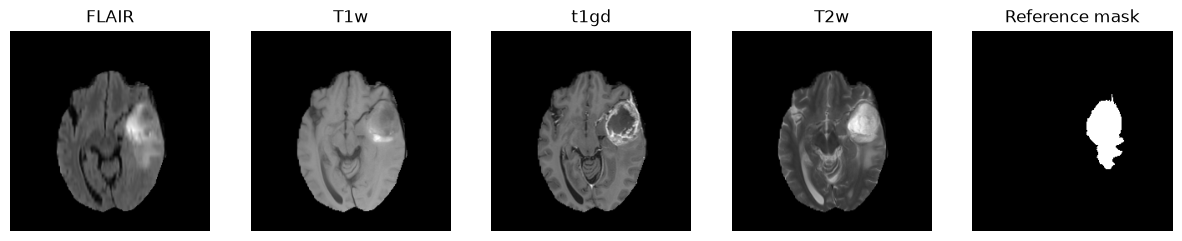

In [6]:

row = split_df.iloc[0]
img = nib.load(DATA_ROOT / row.image_relpath).get_fdata()
lab = np.asarray(nib.load(DATA_ROOT / row.label_relpath).dataobj)

z = int(np.argmax((lab > 0).sum(axis=(0, 1))))   # axial slice with the most tumor

fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))

for i, name in enumerate(channel_order):
    axes[i].imshow(np.rot90(img[:, :, z, i]), cmap="gray")
    axes[i].set_title(name)
axes[4].imshow(np.rot90(lab[:, :, z] > 0), cmap="gray")

axes[4].set_title("Reference mask")
for ax in axes:
    ax.axis("off")
plt.show()

_Interpretation:_

FLAIR: shows a bright region of tumor.

T1w: shows only a subtle change. 

t1gd: shows a bright ring around a darker center, the enhancing tumor border 

T2w: shows a bright, well-defined region. 

### A4. Reference in axial / coronal / sagittal; why index order is insufficient [3]

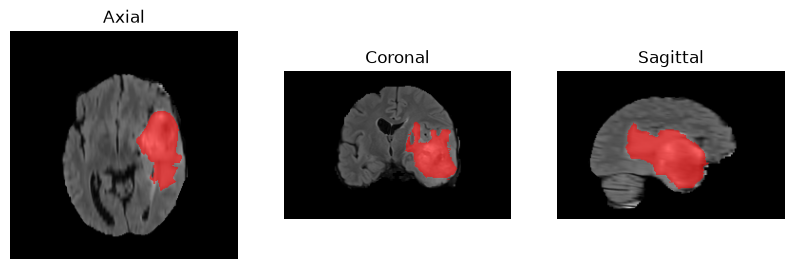

In [7]:
cx, cy, cz = [int(round(c)) for c in ndimage.center_of_mass(lab > 0)]   # tumor center

views = {
    "Axial":    (img[:, :, cz, 0], lab[:, :, cz]),
    "Coronal":  (img[:, cy, :, 0], lab[:, cy, :]),
    "Sagittal": (img[cx, :, :, 0], lab[cx, :, :]),
}

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))

for ax, (name, (im, m)) in zip(axes, views.items()):
    tumor = np.rot90(m > 0)
    ax.imshow(np.rot90(im), cmap="gray")
    ax.imshow(np.ma.masked_where(~tumor, tumor), cmap="autumn", alpha=0.6)
    ax.set_title(name)
    ax.axis("off")

plt.show()

_Interpretation:_ 

The array index does not suggest its orientation. The same indices can mean difference positions. The affine converts it to mm in a direction, without it the array does not have a meaning.

## B. Case-level split (8)

### B1. Use assignment2_split.csv exactly [2]

In [8]:
split_df = pd.read_csv(SPLIT_FILE)
print(split_df.head())
print("columns:", split_df.columns.tolist())
print("rows:", len(split_df))
print("split counts:", split_df["split"].value_counts())
print("unique case_ids:", split_df["case_id"].nunique())


     case_id  split              image_relpath              label_relpath
0  BRATS_001  train  imagesTr/BRATS_001.nii.gz  labelsTr/BRATS_001.nii.gz
1  BRATS_002   test  imagesTr/BRATS_002.nii.gz  labelsTr/BRATS_002.nii.gz
2  BRATS_003  train  imagesTr/BRATS_003.nii.gz  labelsTr/BRATS_003.nii.gz
3  BRATS_004  train  imagesTr/BRATS_004.nii.gz  labelsTr/BRATS_004.nii.gz
4  BRATS_005  train  imagesTr/BRATS_005.nii.gz  labelsTr/BRATS_005.nii.gz
columns: ['case_id', 'split', 'image_relpath', 'label_relpath']
rows: 484
split counts: split
train         338
test           73
validation     73
Name: count, dtype: int64
unique case_ids: 484


### B2. Files exist; case IDs disjoint across splits [3]

In [9]:
missing = [p for r in split_df.itertuples() for p in (DATA_ROOT / r.image_relpath, DATA_ROOT / r.label_relpath) if not p.exists()]

print(f"Missing files: {len(missing)}")

print("duplicate case_ids:", split_df["case_id"].duplicated().sum())

Missing files: 0
duplicate case_ids: 0


_Interpretation:_

No patient can appear in multiple splits.

### B3. Case counts + tumor volume distribution per split (test labels otherwise unused) [3]

In [10]:
vols = []
for r in tqdm(split_df.itertuples(), total=len(split_df)):
    lab = nib.load(DATA_ROOT / r.label_relpath)
    voxel_ml = float(np.prod(lab.header.get_zooms()[:3])) / 1000
    vols.append(np.count_nonzero(np.asarray(lab.dataobj)) * voxel_ml)

vol_df = split_df[["case_id", "split"]].assign(tumor_ml=vols)
display(vol_df.groupby("split")["tumor_ml"].describe().loc[["train", "validation", "test"]].round(1))

  0%|          | 0/484 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,338.0,103.0,57.0,8.5,60.0,95.5,143.9,265.3
validation,73.0,100.8,63.0,7.3,51.9,91.6,148.1,266.9
test,73.0,107.4,66.3,10.1,54.4,89.1,157.7,318.3


_Interpretation:_ 

There are 338 train, 73 validation and 73 test samples. From the mean and min/max we can see that the test split has a larger mean and max but a smaller median, suggesting that it might be right skewed.

## C. Preprocessing (12)

### C1. Geometry check across 4 channels + label; target grid if resampling [3]

In [11]:
geoms, mismatch = set(), []
for r in split_df.itertuples():
    img = nib.load(DATA_ROOT / r.image_relpath)
    lab = nib.load(DATA_ROOT / r.label_relpath)
    geoms.add((img.shape, img.header.get_zooms()[:3]))
    if not np.allclose(img.affine, lab.affine):
        mismatch.append(r.case_id)

print(f"Unique image geometries: {len(geoms)}")
print(f"Cases with mismatched affine matrices: {len(mismatch)}")

Unique image geometries: 1
Cases with mismatched affine matrices: 0


_Interpretation:_

All 484 cases share one grid: shape (240, 240, 155), and every label has the same shape and affine as its image.

### C2. Linear (MRI) / nearest (label) interpolation; labels remain valid [2]

In [12]:
row = split_df.iloc[0]
mri = nib.load(DATA_ROOT / row.image_relpath).get_fdata()[:, :, :, 0]   # FLAIR channel
lab = nib.load(DATA_ROOT / row.label_relpath).get_fdata()

mri_small = ndimage.zoom(mri, 0.5, order=1)       # linear: for MRI
lab_nearest = ndimage.zoom(lab, 0.5, order=0)     # nearest neighbor: for labels
lab_linear = ndimage.zoom(lab, 0.5, order=1)      # linear on labels (the wrong way)

print("original label values:", np.unique(lab))
print("nearest-neighbor label values:", np.unique(lab_nearest))
print("linear: number of different label values:", len(np.unique(lab_linear)))

original label values: [0. 1. 2. 3.]
nearest-neighbor label values: [0. 1. 2. 3.]
linear: number of different label values: 2113


_Interpretation:_ 

Nearest-neighbor kept exactly the original label values {0, 1, 2, 3}, whereas linear interpolation produced 2113 different values.

### C3. Non-zero-voxel normalization; report mean/std [3]

In [13]:
row = split_df.iloc[0]
raw = nib.load(DATA_ROOT / row.image_relpath).get_fdata()

for c, name in enumerate(channel_order):
    channel = raw[:, :, :, c]
    brain = channel[channel != 0]            # keep only the non-zero (brain) voxels
    mean, std = brain.mean(), brain.std()
    normalized = (brain - mean) / std

    print(name, "| before: mean", round(mean, 1), "std", round(std, 1),
          "| after: mean", round(normalized.mean(), 3), "std", round(normalized.std(), 3))

FLAIR | before: mean 516.3 std 211.6 | after: mean -0.0 std 1.0
T1w | before: mean 780.6 std 206.6 | after: mean -0.0 std 1.0
t1gd | before: mean 728.4 std 239.4 | after: mean 0.0 std 1.0
T2w | before: mean 471.8 std 211.0 | after: mean 0.0 std 1.0


_Interpretation:_

After normalization each channel has a mean of 0 and a standard deviation of 1, so the network sees comparable inputs.

### C4. Crop/pad + training-only augmentation; paired before/after example [4]

shape after crop and pad: (144, 176, 144, 4) (144, 176, 144)


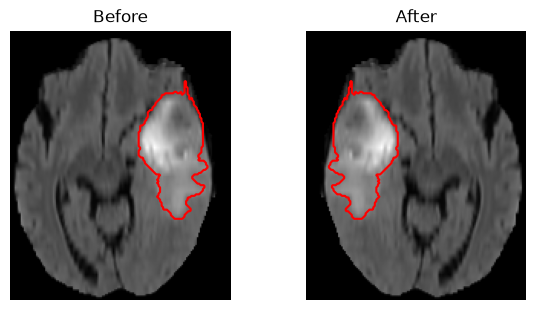

In [14]:
row = split_df.iloc[0]
image = nib.load(DATA_ROOT / row.image_relpath).get_fdata()  
label = np.asarray(nib.load(DATA_ROOT / row.label_relpath).dataobj)

# crop to the box
brain = np.argwhere(image.sum(axis=3) != 0)
lo, hi = brain.min(axis=0), brain.max(axis=0) + 1
image = image[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]]
label = label[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]]

# pad each spatial axis up to a multiple of 16
pad = [(0, (-s) % 16) for s in image.shape[:3]]
image = np.pad(image, pad + [(0, 0)])
label = np.pad(label, pad)
print("shape after crop and pad:", image.shape, label.shape)

# augmentation 
aug_image = image[::-1] * 1.1
aug_label = label[::-1]

# before/after on the slice with the most tumor
z = int(np.argmax((label > 0).sum(axis=(0, 1))))
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
for ax, im, lb, title in [(axes[0], image, label, "Before"), (axes[1], aug_image, aug_label, "After")]:
    ax.imshow(np.rot90(im[:, :, z, 0]), cmap="gray")
    ax.contour(np.rot90(lb[:, :, z] > 0), levels=[0.5], colors="red")
    ax.set_title(title)
    ax.axis("off")
plt.show()


_Interpretation:_ 

Volumes were cropped to the bounding box of non-zero voxels, giving 144 × 176 × 144 after padding each axis to a multiple of 16.

A left-right flip and a mild 10% intensity scaling were chosen as training-only augmentations because (1) tumors occur on either side; (2) the 10% scaling is an untuned and intentional small perturbation. 

## D. Patch-based volumetric training (20)

### D1. Dataset + DataLoader; print and verify one batch [3]

In [15]:
# Cache for fast loading
CACHE_DIR.mkdir(exist_ok=True)

for r in tqdm(list(split_df[split_df["split"] != "test"].itertuples())):
    if (CACHE_DIR / f"{r.case_id}_lab.npy").exists():
        continue                                                

    image = nib.load(DATA_ROOT / r.image_relpath).get_fdata()   
    label = nib.load(DATA_ROOT / r.label_relpath).get_fdata() > 0      

    brain = np.argwhere(image.sum(axis=3) != 0)                      
    lo, hi = brain.min(axis=0), brain.max(axis=0) + 1
    image = image[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]]
    label = label[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]]

    for c in range(4):                            
        channel = image[:, :, :, c]
        nonzero = channel != 0
        channel[nonzero] = (channel[nonzero] - channel[nonzero].mean()) / channel[nonzero].std()

    pad = [(0, max(64, -(-s // 16) * 16) - s) for s in label.shape]   
    image = np.pad(image, pad + [(0, 0)])
    label = np.pad(label, pad)

    np.save(CACHE_DIR / f"{r.case_id}_img.npy", image.transpose(3, 2, 0, 1).astype(np.float16, order="C"))  
    np.save(CACHE_DIR / f"{r.case_id}_lab.npy", label.transpose(2, 0, 1).astype(np.uint8, order="C"))   


  0%|          | 0/411 [00:00<?, ?it/s]

In [ ]:
# D1. Dataset + DataLoader
class PatchDataset(Dataset):
    def __init__(self, split):
        self.cases = split_df[split_df["split"] == split]
        self.size = 64                                    # patch is 64 x 64 x 64

    def __len__(self):
        return len(self.cases)

    def __getitem__(self, i):
        case_id = self.cases.iloc[i].case_id
        image = np.load(CACHE_DIR / f"{case_id}_img.npy", mmap_mode="r")   # [C, D, H, W]
        label = np.load(CACHE_DIR / f"{case_id}_lab.npy", mmap_mode="r")   # [D, H, W]

        s = self.size                                     # pick a random 64-voxel box
        d0 = np.random.randint(label.shape[0] - s + 1)
        h0 = np.random.randint(label.shape[1] - s + 1)
        w0 = np.random.randint(label.shape[2] - s + 1)
        image = np.array(image[:, d0:d0 + s, h0:h0 + s, w0:w0 + s])
        label = np.array(label[d0:d0 + s, h0:h0 + s, w0:w0 + s])

        return torch.tensor(image, dtype=torch.float32), torch.tensor(label, dtype=torch.float32).unsqueeze(0)


train_loader = DataLoader(PatchDataset("train"), batch_size=2, shuffle=True)

x, y = next(iter(train_loader))
print("image batch:", x.shape)
print("mask batch: ", y.shape)
print("mask values:", torch.unique(y))


image batch: torch.Size([2, 4, 64, 64, 64])
mask batch:  torch.Size([2, 1, 64, 64, 64])
mask values: tensor([0., 1.])


_Interpretation:_

A verified batch has image shape [2, 4, 64, 64, 64] (float32) and mask shape [2, 1, 64, 64, 64] containing only the values {0, 1}.

Cache cell saves each train and validation case in `cache/`, with the test cases untouches, so that `PatchDataset` don't have to decompress during training. 

### D2. 3D model: in/out channels, parameter count, patch size [5]

In [17]:

def block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv3d(in_ch, out_ch, 3, padding=1), nn.InstanceNorm3d(out_ch), nn.ReLU(),
        nn.Conv3d(out_ch, out_ch, 3, padding=1), nn.InstanceNorm3d(out_ch), nn.ReLU(),
    )


class UNet3D(nn.Module):
    def __init__(self, in_ch=4, out_ch=1, c=8):
        super().__init__()
        
        self.enc1 = block(in_ch, c)
        self.enc2 = block(c, 2 * c)
        self.enc3 = block(2 * c, 4 * c)
        self.bottom = block(4 * c, 8 * c)
        self.pool = nn.MaxPool3d(2)
        self.up3 = nn.ConvTranspose3d(8 * c, 4 * c, 2, stride=2)
        self.dec3 = block(8 * c, 4 * c)
        self.up2 = nn.ConvTranspose3d(4 * c, 2 * c, 2, stride=2)
        self.dec2 = block(4 * c, 2 * c)
        self.up1 = nn.ConvTranspose3d(2 * c, c, 2, stride=2)
        self.dec1 = block(2 * c, c)
        self.out = nn.Conv3d(c, out_ch, 1)

    def forward(self, x):
        e1 = self.enc1(x) # down path
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        b = self.bottom(self.pool(e3))

        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1)) # up path
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        
        return self.out(d1)   # one score per voxel


model = UNet3D()
x = torch.randn(2, 4, 64, 64, 64)
print("input channels: 4 | output channels: 1 | patch size: 64 x 64 x 64")
print("output shape:", model(x).shape)
print("parameters:", sum(p.numel() for p in model.parameters()))


input channels: 4 | output channels: 1 | patch size: 64 x 64 x 64


output shape: torch.Size([2, 1, 64, 64, 64])
parameters: 351105


_Interpretation:_

A lightweight 3D U-Net with three downsampling steps takes a 4-channel 64 × 64 × 64 patch and outputs a single-channel map of voxel scores of the same size.

### D3. Training with uniform patches: loss, optimizer, LR, budget, seed [4]

In [18]:

ITERATIONS = 1000 # 2000 patches
VAL_EVERY = 50         
LR = 1e-3
BATCH_SIZE = 2

# fixed validation patches
np.random.seed(SEED)
val_set = PatchDataset("validation")
val_pairs = [val_set[i] for i in range(len(val_set))]
val_x = torch.stack([p[0] for p in val_pairs])
val_y = torch.stack([p[1] for p in val_pairs])


def loss_fn(logits, y):                                
    p = torch.sigmoid(logits)
    dice = (2 * (p * y).sum() + 1) / (p.sum() + y.sum() + 1)
    return F.binary_cross_entropy_with_logits(logits, y) + (1 - dice)


def evaluate(model):                              
    model.eval()
    loss, tp, fp, fn = 0, 0, 0, 0
    with torch.no_grad():
        for i in range(0, len(val_x), 8):
            x, y = val_x[i:i + 8].to(DEVICE), val_y[i:i + 8].to(DEVICE)
            logits = model(x)
            loss += loss_fn(logits, y).item() * len(x)
            pred = logits > 0
            tp += (pred & (y == 1)).sum().item()
            fp += (pred & (y == 0)).sum().item()
            fn += (~pred & (y == 1)).sum().item()
    return loss / len(val_x), 2 * tp / (2 * tp + fp + fn + 1e-8)


def train(loader):
    seed_everything(SEED)                             
    model = UNet3D().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history = {"step": [], "train_loss": [], "val_loss": [], "val_dice": []}
    recent, step = [], 0
    while step < ITERATIONS:
        for x, y in loader:
            model.train()
            loss = loss_fn(model(x.to(DEVICE)), y.to(DEVICE))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            recent.append(loss.item())
            step += 1
            if step % VAL_EVERY == 0:
                val_loss, val_dice = evaluate(model)
                for k, v in zip(history, [step, np.mean(recent), val_loss, val_dice]):
                    history[k].append(v)
                print(f"step {step}: train loss {np.mean(recent):.3f} | val loss {val_loss:.3f} | val Dice {val_dice:.3f}")
                recent = []
            if step == ITERATIONS:
                break
    return model, history


print(f"loss: BCE + soft Dice | optimizer: Adam | LR: {LR} | budget: {ITERATIONS} steps x batch {BATCH_SIZE} | seed: {SEED}")
uniform_loader = DataLoader(PatchDataset("train"), batch_size=BATCH_SIZE, shuffle=True)
uniform_model, uniform_history = train(uniform_loader)
torch.save(uniform_model.state_dict(), OUT_DIR / "uniform.pt")


loss: BCE + soft Dice | optimizer: Adam | LR: 0.001 | budget: 1000 steps x batch 2 | seed: 0


step 50: train loss 1.377 | val loss 1.369 | val Dice 0.390


step 100: train loss 1.297 | val loss 1.291 | val Dice 0.462


step 150: train loss 1.236 | val loss 1.237 | val Dice 0.490


step 200: train loss 1.125 | val loss 1.187 | val Dice 0.479


...

step 800: train loss 0.767 | val loss 0.809 | val Dice 0.671


step 850: train loss 0.839 | val loss 0.806 | val Dice 0.660


step 900: train loss 0.766 | val loss 0.783 | val Dice 0.656


step 950: train loss 0.779 | val loss 0.744 | val Dice 0.712


step 1000: train loss 0.696 | val loss 0.726 | val Dice 0.702


_Interpretation:_ 

Training loss fell from 1.377 to 0.696, validation loss from 1.369 to 0.726, and patch-level validation Dice rose from 0.39 to 0.702. Validation loss stayed below training loss, because the training loss is averaged over the preceding 50 steps while the model improves, so there is no sign of overfitting. However, both losses were still decreasing at the end and the best Dice occurred at the final step, which indicates underfitting caused by the small training budget. 

### D4. Training with tumor-aware patches (same init + budget); tumor-patch fraction for both [5]

In [19]:

TUMOR_PROB = 0.5 # chance that a patch is centered on a random tumor voxel


class TumorAwareDataset(PatchDataset):
    def __getitem__(self, i):
        case_id = self.cases.iloc[i].case_id
        image = np.load(CACHE_DIR / f"{case_id}_img.npy", mmap_mode="r") 
        label = np.load(CACHE_DIR / f"{case_id}_lab.npy", mmap_mode="r") 
        s = self.size

        if np.random.rand() < TUMOR_PROB:               
            tumor = np.argwhere(label)
            center = tumor[np.random.randint(len(tumor))]
            d0, h0, w0 = [int(np.clip(c - s // 2, 0, n - s)) for c, n in zip(center, label.shape)]
        else:                                            
            d0 = np.random.randint(label.shape[0] - s + 1)
            h0 = np.random.randint(label.shape[1] - s + 1)
            w0 = np.random.randint(label.shape[2] - s + 1)

        image = np.array(image[:, d0:d0 + s, h0:h0 + s, w0:w0 + s])
        label = np.array(label[d0:d0 + s, h0:h0 + s, w0:w0 + s])
        return torch.tensor(image, dtype=torch.float32), torch.tensor(label, dtype=torch.float32).unsqueeze(0)


def tumor_fraction(loader):                            
    n, with_tumor = 0, 0
    for x, y in loader:
        with_tumor += (y.sum(dim=(1, 2, 3, 4)) > 0).sum().item()
        n += len(y)
    return with_tumor / n


tumor_loader = DataLoader(TumorAwareDataset("train"), batch_size=BATCH_SIZE, shuffle=True)

seed_everything(SEED)
print("patches containing tumor | uniform:", round(tumor_fraction(uniform_loader), 3),
      "| tumor-aware:", round(tumor_fraction(tumor_loader), 3))

tumor_model, tumor_history = train(tumor_loader)
torch.save(tumor_model.state_dict(), OUT_DIR / "tumor_aware.pt")


patches containing tumor | uniform: 0.772 | tumor-aware: 0.87


step 50: train loss 1.203 | val loss 1.400 | val Dice 0.292


step 100: train loss 1.062 | val loss 1.332 | val Dice 0.358


step 150: train loss 1.030 | val loss 1.272 | val Dice 0.409


step 200: train loss 0.926 | val loss 1.247 | val Dice 0.391


...

step 800: train loss 0.615 | val loss 0.865 | val Dice 0.640


step 850: train loss 0.638 | val loss 0.857 | val Dice 0.619


step 900: train loss 0.524 | val loss 0.839 | val Dice 0.627


step 950: train loss 0.596 | val loss 0.784 | val Dice 0.679


step 1000: train loss 0.513 | val loss 0.777 | val Dice 0.681


_Interpretation:_ 


The fraction of training patches containing tumor was 0.772 for the uniform sampler and 0.870 for the tumor-aware sampler. Training loss fell from 1.203 to 0.513, validation loss from 1.400 to 0.777, and patch-level validation Dice rose from 0.292 to 0.681. Unlike D3, the training loss ended below the validation loss. However, validation loss continuously decreased, so there is no sign of overfitting. Both losses were still decreasing and the best Dice occurred at the final steps, which indicates underfitting caused by the small training budget.

### D5. Train/val loss + val Dice curves; diagnosis without test data [3]

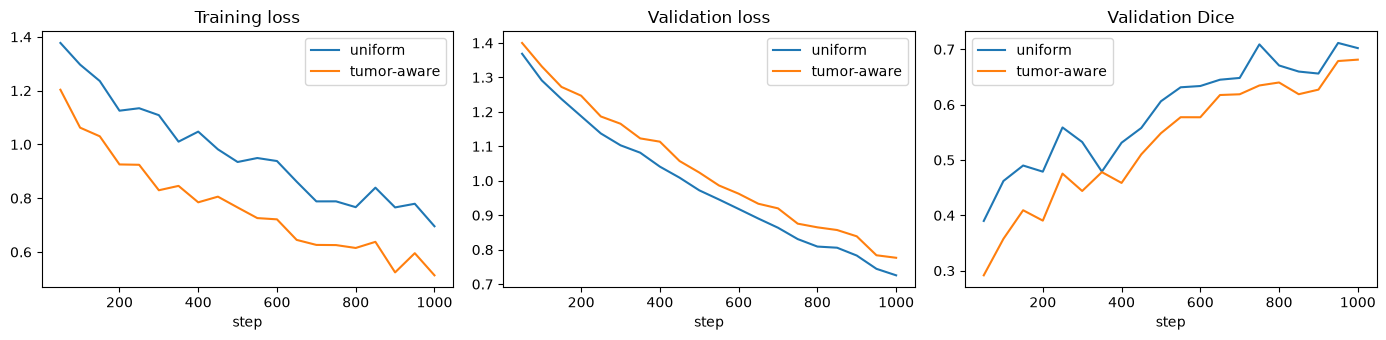

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

for history, name in [(uniform_history, "uniform"), (tumor_history, "tumor-aware")]:
    axes[0].plot(history["step"], history["train_loss"], label=name)
    axes[1].plot(history["step"], history["val_loss"], label=name)
    axes[2].plot(history["step"], history["val_dice"], label=name)

for ax, title in zip(axes, ["Training loss", "Validation loss", "Validation Dice"]):
    ax.set_title(title)
    ax.set_xlabel("step")
    ax.legend()


plt.tight_layout()
plt.show()

_Interpretation:_ 

Validation loss fell at almost every checkpoint and validation Dice rose, with both still improving at step 1000, which indicates underfitting caused by the small training budget, since neither validation loss rose. Validation Dice fluctuated between checkpoints, may be because of the small batch size. The tumor-aware run has the lower training loss but higher val loss. 

## E. Controlled sampling comparison (10)

### E1. Same architecture, split, loss, budget [3]

In [21]:
n_uniform = sum(p.numel() for p in uniform_model.parameters())
n_tumor = sum(p.numel() for p in tumor_model.parameters())

seed_everything(SEED); init_a = UNet3D()           
seed_everything(SEED); init_b = UNet3D()
same_init = all(torch.equal(a, b) for a, b in zip(init_a.state_dict().values(), init_b.state_dict().values()))

comparison = pd.DataFrame({
    "uniform": [n_uniform, "train / validation", "BCE + soft Dice", "Adam", LR, BATCH_SIZE, ITERATIONS, SEED, "uniform random"],
    "tumor-aware": [n_tumor, "train / validation", "BCE + soft Dice", "Adam", LR, BATCH_SIZE, ITERATIONS, SEED, f"{TUMOR_PROB} chance centered on tumor"],
}, 
index=["parameters", "cases used", "loss", "optimizer", "learning rate", "batch size", "steps", "seed", "patch sampling"])

display(comparison)
print("identical initial weights:", same_init)

,uniform,tumor-aware
parameters,351105,351105
cases used,train / validation,train / validation
loss,BCE + soft Dice,BCE + soft Dice
optimizer,Adam,Adam
learning rate,0.001,0.001
batch size,2,2
steps,1000,1000
seed,0,0
patch sampling,uniform random,0.5 chance centered on tumor


identical initial weights: True


_Interpretation:_ 

Both models use the same 3D U-Net (351,105 parameters), the same train/validation split, the same BCE + soft Dice loss, Adam.

### E2. Val Dice, sensitivity, false-positive volume; mechanism [4]

In [22]:
def val_metrics(model):
    model.eval()
    tp, fp, fn = 0, 0, 0
    with torch.no_grad():
        for i in range(0, len(val_x), 8):
            x, y = val_x[i:i + 8].to(DEVICE), val_y[i:i + 8].to(DEVICE)
            pred = model(x) > 0
            tp += (pred & (y == 1)).sum().item()
            fp += (pred & (y == 0)).sum().item()
            fn += (~pred & (y == 1)).sum().item()

    dice = 2 * tp / (2 * tp + fp + fn + 1e-8)
    sensitivity = tp / (tp + fn + 1e-8)
    fp_ml = fp / 1000 / len(val_x) # mL per patch
    return {"Dice": dice, "sensitivity": sensitivity, "FP volume per patch (mL)": fp_ml}


results = pd.DataFrame({"uniform": val_metrics(uniform_model), "tumor-aware": val_metrics(tumor_model)}).T
display(results.round(3))


,Dice,sensitivity,FP volume per patch (mL)
uniform,0.702,0.737,4.627
tumor-aware,0.681,0.818,7.471


_Interpretation:_ 

umor-aware sampling shows the network tumor in 87% of its training patches instead of 77%, so it learns to find tumor and misses less, but it sees less healthy brain and over-predicts more, and the extra false positives outweigh the sensitivity gain in Dice. The Dice difference of 0.02 is small so the comparison is inconclusive.


### E3. Final configuration from validation only; downside of over-sampling [3]

In [23]:

final = results["Dice"].idxmax() # highest validation Dice
final_model = uniform_model if final == "uniform" else tumor_model

print(results.round(3))
print("Final configuration:", final)

              Dice  sensitivity  FP volume per patch (mL)
uniform      0.702        0.737                     4.627
tumor-aware  0.681        0.818                     7.471
Final configuration: uniform


_Interpretation:_ 

The uniform sampler was selected as the final configuration because it had the higher validation Dice.

## F. Full-volume reconstruction and test evaluation (15)

### F1. Overlapping sliding-window inference; patch, stride, overlap, blending [4]

In [24]:
PATCH = 64
STRIDE = 32

def load_case(row):
    image = nib.load(DATA_ROOT / row.image_relpath).get_fdata()
    label = nib.load(DATA_ROOT / row.label_relpath).get_fdata() > 0
    brain = np.argwhere(image.sum(axis=3) != 0)
    lo, hi = brain.min(axis=0), brain.max(axis=0) + 1
    image = image[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]]
    label = label[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]]

    for c in range(4):
        channel = image[:, :, :, c]
        nonzero = channel != 0
        channel[nonzero] = (channel[nonzero] - channel[nonzero].mean()) / channel[nonzero].std()

    pad = [(0, max(PATCH, -(-s // STRIDE) * STRIDE) - s) for s in label.shape]
    image = np.pad(image, pad + [(0, 0)])
    label = np.pad(label, pad)
    return torch.tensor(image.transpose(3, 2, 0, 1), dtype=torch.float32), label.transpose(2, 0, 1)

def window_starts(n):
    return sorted(set(range(0, n - PATCH + 1, STRIDE)) | {n - PATCH})

def sliding_window(model, image):
    _, D, H, W = image.shape
    prob_sum = torch.zeros(D, H, W)
    count = torch.zeros(D, H, W)
    model.eval()
    with torch.no_grad():
        for d in window_starts(D):
            for h in window_starts(H):
                for w in window_starts(W):
                    patch = image[:, d:d + PATCH, h:h + PATCH, w:w + PATCH]
                    prob = torch.sigmoid(model(patch[None].to(DEVICE)))[0, 0].cpu()
                    prob_sum[d:d + PATCH, h:h + PATCH, w:w + PATCH] += prob
                    count[d:d + PATCH, h:h + PATCH, w:w + PATCH] += 1

    return prob_sum / count

# demo one val case
row = split_df[split_df["split"] == "validation"].iloc[0]
image, label = load_case(row)
start = time.time()
prob = sliding_window(final_model, image)
pred = prob.numpy() > 0.5
dice = 2 * (pred & label).sum() / (pred.sum() + label.sum())
print(f"image {tuple(image.shape)} to probability map {tuple(prob.shape)}, range {prob.min():.2f} to {prob.max():.2f}")
print(f"patch {PATCH}, stride {STRIDE}, overlap {100 * (PATCH - STRIDE) // PATCH}% | time {time.time() - start:.1f}s | Dice {dice:.4f}")

image (4, 160, 160, 192) to probability map (160, 160, 192), range 0.01 to 0.95
patch 64, stride 32, overlap 50% | time 2.5s | Dice 0.8629


_Interpretation:_ 

Inference slides a 64 × 64 × 64 window over each volume with a stride of 32 voxels (50% overlap).

### F2. Test: Dice, IoU, sensitivity, HD95 (mm); mean/SD/median; # empty predictions [4]

In [25]:
def hd95(pred, ref, spacing=1.0):                     # 95th percentile surface distance in mm
    if pred.sum() == 0:
        return np.nan
    pred_surface = pred & ~ndimage.binary_erosion(pred)
    ref_surface = ref & ~ndimage.binary_erosion(ref)
    dist_to_ref = ndimage.distance_transform_edt(~ref_surface, sampling=spacing)
    dist_to_pred = ndimage.distance_transform_edt(~pred_surface, sampling=spacing)
    distances = np.concatenate([dist_to_ref[pred_surface], dist_to_pred[ref_surface]])
    return np.percentile(distances, 95)


test_preds, test_refs = {}, {}                          # full-volume predictions for every test case
for r in tqdm(list(split_df[split_df["split"] == "test"].itertuples())):
    image, ref = load_case(r)
    test_preds[r.case_id] = sliding_window(final_model, image).numpy() > 0.5
    test_refs[r.case_id] = ref


rows = []
for case_id, pred in test_preds.items():
    ref = test_refs[case_id]
    tp = (pred & ref).sum()
    fp = (pred & ~ref).sum()
    fn = (~pred & ref).sum()
    rows.append({
        "case_id": case_id,
        "Dice": 2 * tp / (2 * tp + fp + fn),
        "IoU": tp / (tp + fp + fn),
        "sensitivity": tp / (tp + fn),
        "HD95 (mm)": hd95(pred, ref),
        "pred_ml": pred.sum() / 1000,
        "ref_ml": ref.sum() / 1000,
    })

test_df = pd.DataFrame(rows)
display(test_df[["Dice", "IoU", "sensitivity", "HD95 (mm)"]].agg(["mean", "std", "median"]).round(3))
print("empty predictions:", int((test_df["pred_ml"] == 0).sum()), "of", len(test_df))




  0%|          | 0/73 [00:00<?, ?it/s]

,Dice,IoU,sensitivity,HD95 (mm)
mean,0.771,0.646,0.823,38.646
std,0.144,0.172,0.141,29.134
median,0.799,0.665,0.871,38.013


empty predictions: 0 of 73


_Interpretation:_

On the 73 untouched test cases, the model reached a mean Dice of 0.771 ± 0.144 (median 0.799), IoU of 0.646, sensitivity of 0.823 and HD95 of 38.6 ± 29.1 mm (median 38.0), with no empty predictions. The large SD and the high HD95 relative to Dice show a few poor cases and stray false positive regions far from the tumor, which Dice barely notices.

### F3. Volume (mL) from spacing; absolute and % volume error per case [3]

In [26]:
voxel_ml = 1.0 * 1.0 * 1.0 / 1000.0

test_df["ref_ml"] = [test_refs[c].sum() * voxel_ml for c in test_df["case_id"]]
test_df["pred_ml"] = [test_preds[c].sum() * voxel_ml for c in test_df["case_id"]]
test_df["abs_error_ml"] = (test_df["pred_ml"] - test_df["ref_ml"]).abs()
test_df["pct_error"] = 100 * test_df["abs_error_ml"] / test_df["ref_ml"]

display(test_df[["case_id", "ref_ml", "pred_ml", "abs_error_ml", "pct_error"]].round(1))
display(test_df[["abs_error_ml", "pct_error"]].agg(["mean", "std", "median"]).round(1))


,case_id,ref_ml,pred_ml,abs_error_ml,pct_error
0,BRATS_002,63.1,102.0,39.0,61.8
1,BRATS_012,21.6,55.9,34.3,158.6
2,BRATS_016,82.7,101.5,18.8,22.7
3,BRATS_033,114.0,112.2,1.8,1.6
4,BRATS_039,37.0,40.2,3.2,8.7
...,...,...,...,...,...
68,BRATS_462,38.3,50.7,12.4,32.4
69,BRATS_466,16.7,70.9,54.2,323.5
70,BRATS_467,157.7,112.6,45.1,28.6
71,BRATS_481,57.2,58.6,1.5,2.5


,abs_error_ml,pct_error
mean,27.4,46.1
std,26.9,110.3
median,20.8,20.0


_Interpretation:_ 

The mean absolute volume error was 27.4 mL (median 20.8 mL), and the mean percentage error was 46.1% with median 20.0%. The mean percentage is much larger than the median because small tumors produce very large relative errors, for example BRATS_466.

### F4. Connected-component postprocessing; before vs after [4]

In [27]:

def keep_largest(pred):
    labeled, n = ndimage.label(pred) 
    if n <= 1:
        return pred
                        
    sizes = ndimage.sum(pred, labeled, range(1, n + 1)) # voxel count
    return labeled == (np.argmax(sizes) + 1) # keep the biggest


def scores(preds):
    rows = []
    for case_id, pred in preds.items():
        ref = test_refs[case_id]
        tp = (pred & ref).sum()
        fp = (pred & ~ref).sum()
        fn = (~pred & ref).sum()
        
        rows.append({"Dice": 2 * tp / (2 * tp + fp + fn), "IoU": tp / (tp + fp + fn),
                     "sensitivity": tp / (tp + fn), "HD95 (mm)": hd95(pred, ref)})
        
    return pd.DataFrame(rows)


before = scores(test_preds)
after = scores({c: keep_largest(p) for c, p in test_preds.items()})

display(pd.DataFrame({"before mean": before.mean(), "after mean": after.mean(), "before median": before.median(), "after median": after.median()}).round(3))
print("cases with more than one component:", sum(ndimage.label(p)[1] > 1 for p in test_preds.values()))


,before mean,after mean,before median,after median
Dice,0.771,0.825,0.799,0.866
IoU,0.646,0.718,0.665,0.764
sensitivity,0.823,0.810,0.871,0.859
HD95 (mm),38.646,10.530,38.013,5.916


cases with more than one component: 73


_Interpretation:_ 

Keeping only the largest connected component raised mean Dice from 0.771 to 0.825 and cut mean HD95 from 38.6 to 10.5 mm, at a small cost in sensitivity (0.823 to 0.810), because every one of the 73 predictions contained extra blobs that were mostly false positives. 

## G. Three-plane error analysis and limitations (10)

### G1. Best / median / worst by Dice in 3 planes with overlays [3]

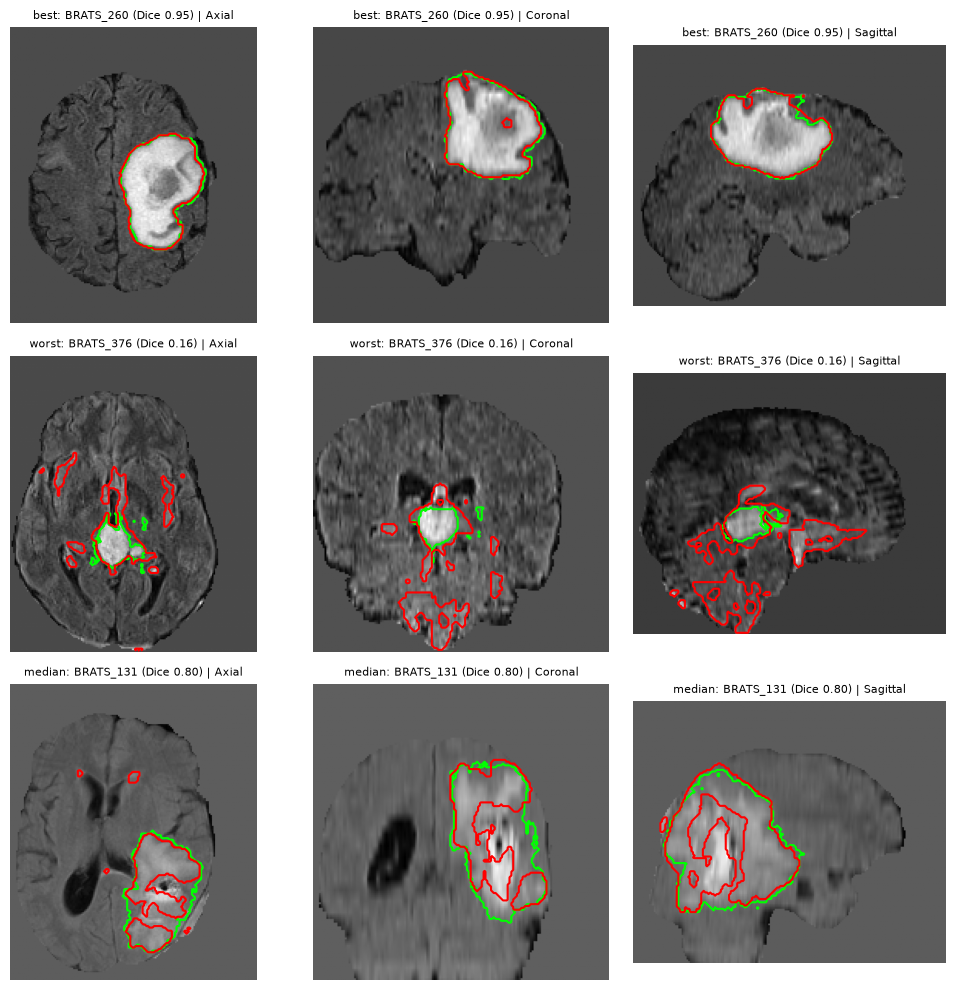

In [ ]:
dice = test_df["Dice"]
picks = {"best": dice.idxmax(), "worst": dice.idxmin(), "median": dice.sub(dice.median()).abs().idxmin()}

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for i, (name, idx) in enumerate(picks.items()):
    case_id = test_df.loc[idx, "case_id"]
    image, _ = load_case(split_df[split_df["case_id"] == case_id].iloc[0])
    flair = image[0].numpy().transpose(1, 2, 0) 
    ref = test_refs[case_id].transpose(1, 2, 0)
    pred = test_preds[case_id].transpose(1, 2, 0)
    cx, cy, cz = [int(round(c)) for c in ndimage.center_of_mass(ref)]

    planes = {
        "Axial":    (flair[:, :, cz], ref[:, :, cz], pred[:, :, cz]),
        "Coronal":  (flair[:, cy, :], ref[:, cy, :], pred[:, cy, :]),
        "Sagittal": (flair[cx, :, :], ref[cx, :, :], pred[cx, :, :]),
    }
    
    for j, (plane, (im, r, p)) in enumerate(planes.items()):
        ax = axes[i, j]
        ax.imshow(np.rot90(im), cmap="gray")
        ax.contour(np.rot90(r), levels=[0.5], colors="lime")   # reference: green
        ax.contour(np.rot90(p), levels=[0.5], colors="red")    # prediction: red
        ax.set_title(f"{name}: {case_id} (Dice {test_df.loc[idx, 'Dice']:.2f}) | {plane}", fontsize=8)
        ax.axis("off")

plt.tight_layout()
plt.show()

_Interpretation:_

Best (BRATS_260, Dice 0.95): the red and green outlines almost coincide in all three planes.

Worst (BRATS_376, Dice 0.16): the reference is a small, deep lesion near the midline, and the prediction does cover it, but it also draws many large red regions elsewhere, so false positives far from the tumor dominate the error.

Median (BRATS_131, Dice 0.80): the red outline follows the outer edge of the large tumor, but there are red outlines inside it that leave holes, so the model misses parts of the interior.

### G2. TP / FP / FN colouring; link an error to boundary / small structure / patch context [3]

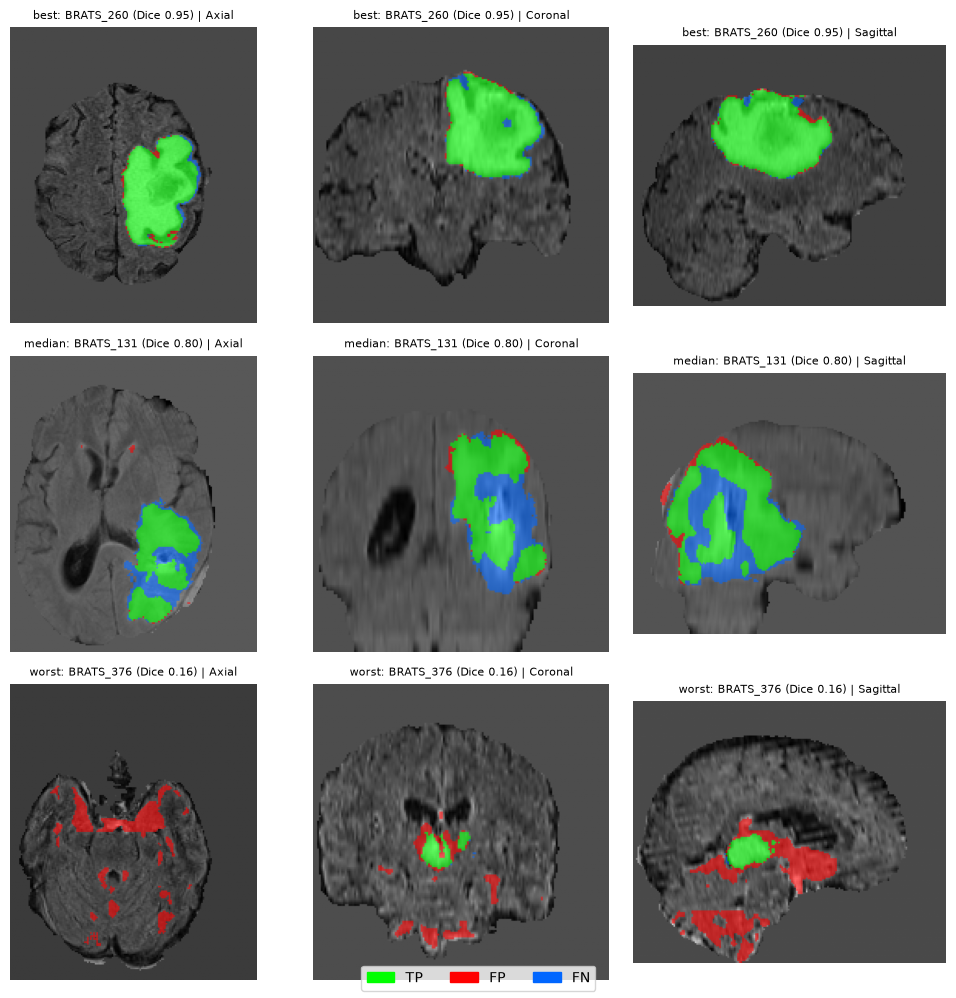

In [ ]:

dice = test_df["Dice"]
picks = {
    "best": dice.idxmax(),
    "median": (dice - dice.median()).abs().idxmin(),
    "worst": dice.idxmin(),
}

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for i, (name, idx) in enumerate(picks.items()):
    case_id = test_df.loc[idx, "case_id"]
    image, _ = load_case(split_df[split_df["case_id"] == case_id].iloc[0])
    flair = image[0].numpy().transpose(1, 2, 0)                   # back to (x, y, z)
    ref = test_refs[case_id].transpose(1, 2, 0)
    pred = test_preds[case_id].transpose(1, 2, 0)
    cx, cy, cz = [int(round(c)) for c in ndimage.center_of_mass(ref ^ pred)]   # center of the errors

    planes = {
        "Axial":    (flair[:, :, cz], ref[:, :, cz], pred[:, :, cz]),
        "Coronal":  (flair[:, cy, :], ref[:, cy, :], pred[:, cy, :]),
        "Sagittal": (flair[cx, :, :], ref[cx, :, :], pred[cx, :, :]),
    }
    for j, (plane, (im, r, p)) in enumerate(planes.items()):
        overlay = np.zeros(r.shape + (4,))
        overlay[r & p] = [0, 1, 0, 0.6]     
        overlay[~r & p] = [1, 0, 0, 0.6]
        overlay[r & ~p] = [0, 0.4, 1, 0.6]   
        ax = axes[i, j]
        ax.imshow(np.rot90(im), cmap="gray")
        ax.imshow(np.rot90(overlay))
        ax.set_title(f"{name}: {case_id} (Dice {test_df.loc[idx, 'Dice']:.2f}) | {plane}", fontsize=8)
        ax.axis("off")

fig.legend(handles=[Patch(color=(0, 1, 0), label="TP"), Patch(color=(1, 0, 0), label="FP"),
                    Patch(color=(0, 0.4, 1), label="FN")], loc="lower center", ncol=3)
plt.tight_layout()
plt.show()


_Interpretation:_

Best (BRATS_260, Dice 0.95): the tumor is almost entirely green. 

Median (BRATS_131, Dice 0.80): there is very little red, but a large blue region inside and below the tumor, so the main error is false negatives: the model under-segmented part of a large tumor and missed its interior. 

Worst (BRATS_376, Dice 0.16): the small reference tumor (10 mL) is found, shown as the green patch in the center, but large red regions appear along the skull base and in the posterior fossa, so false positives dominate. 

### G3. Dice vs HD95 vs volume error [2]

In [ ]:
dice = test_df["Dice"]
picks = {
    "best": dice.idxmax(),
    "median": (dice - dice.median()).abs().idxmin(),
    "worst": dice.idxmin(),
}

columns = ["case_id", "Dice", "HD95 (mm)", "ref_ml", "pred_ml", "abs_error_ml", "pct_error"]
display(test_df.loc[list(picks.values()), columns].set_axis(list(picks), axis=0).round(2))


,case_id,Dice,HD95 (mm),ref_ml,pred_ml,abs_error_ml,pct_error
best,BRATS_260,0.95,2.24,108.39,105.66,2.73,2.52
median,BRATS_131,0.80,11.05,173.33,130.84,42.49,24.51
worst,BRATS_376,0.16,44.83,10.10,99.80,89.70,888.04


_Interpretation:_ 

The best case (BRATS_260) is good on all three: Dice 0.95, HD95 2.2 mm, volume error 2.5%. In the median case (BRATS_131) a fair Dice (0.80) coexists with an HD95 of 11.1 mm and a 24.5% volume error, because the model missed the tumor interior. In the worst case (BRATS_376) Dice is 0.16, HD95 is 44.8 mm and the volume error is 888%, because a small reference tumor (10 mL) was swamped by about 100 mL of false positives. So no single metric is enough

### G4. ≥3 limitations [2]

1. Small training budget: each model was trained for only 1000 steps (2000 patches) with a 351,105-parameter 3D U-Net. Validation loss and Dice were still improving at the end, so the models are undertrained.

2. One run per condition and run-to-run variability: each sampler was trained once with one seed, and results differ between runs of the same code because GPU computation is not fully repeatable. This variation is larger than the 0.02 Dice gap between the samplers (validation Dice 0.774 vs 0.702), so the sampler comparison is inconclusive.

3. No external-site validation: all cases come from one dataset (the Medical Segmentation Decathlon, derived from BraTS) and were split at the case level, so performance on other scanners, protocols or hospitals is unknown